# Codebook workflow
Run one step, review its results, then decide what to do next. One session folder represents one experiment. The Python implementation is in `simple_experiment.py`. This is the current pipeline; the older `codebook_iteration.ipynb` is kept as a historical reference. See [HOW_IT_WORKS.md](HOW_IT_WORKS.md) for a beginner walkthrough.

**Dataset numbers identify input files. Codebook versions identify successive codebooks.** Version numbers only go up: 1, 2, 3 across all datasets and models. There is no resetting revision counter.

Every request starts with `preview=True`. It saves the request locally and prints a short summary. Change that call to `preview=False` when ready to submit. Review cells never submit requests. For batch classifications, rerun the review cell until ready. Codebook generation and revision always stream and save the codebook immediately. Keep optional steps unrun until you decide you need them.


In [2]:
%load_ext autoreload
%autoreload 2

import os
from dotenv import load_dotenv
from simple_experiment import Experiment

load_dotenv("../.env")

# experiment = Experiment(
#     session_dir="grimmer_Aluna_Bdeepseek",
#     model_b="deepseek/deepseek-v4.1-flash:nitro",
#     model_a="openai/gpt-6-luna:nitro",
#     api_key=os.getenv("OPENROUTER_API_KEY"),
#     mode="stream",  # Classification mode. Codebooks always use stream.
#     n_runs=25,
# )

experiment = Experiment(
    session_dir="emotive_rhetoric_new_pipeline_fix",
    model_a="deepseek/deepseek-v4.1-flash:nitro",
    model_b="openai/gpt-6-luna:nitro",
    api_key=os.getenv("OPENROUTER_API_KEY"),
    mode="stream",  # Classification mode. Codebooks always use stream.
    n_runs=25,
)


## 1. Initial coding
Code dataset 0 without a codebook. Existing runs are reused if you rerun the submission cell. Review prints alpha and shows document agreement.


In [104]:
experiment.code(datasets=0, preview=False)


Run 1/25
Run 2/25
Run 3/25
Run 4/25
Run 5/25
Run 6/25
Run 7/25
Run 8/25
Run 9/25
Run 10/25
Run 11/25
Run 12/25
Run 13/25
Run 14/25
Run 15/25
Run 16/25
Run 17/25
Run 18/25
Run 19/25
Run 20/25
Run 21/25
Run 22/25
Run 23/25
Run 24/25
Run 25/25
Submitted/resumed: model A, datasets [0], no codebook, 25 runs (stream). C:\Users\yjjby\Documents\projects\Topic-Conceptualization\iterative_codebook_making\emotive_rhetoric_new_pipeline_fix_Aluna_Bdeepseek\out\coding\datasets-0\no-codebook\model-A


Krippendorff's alpha: 0.8510


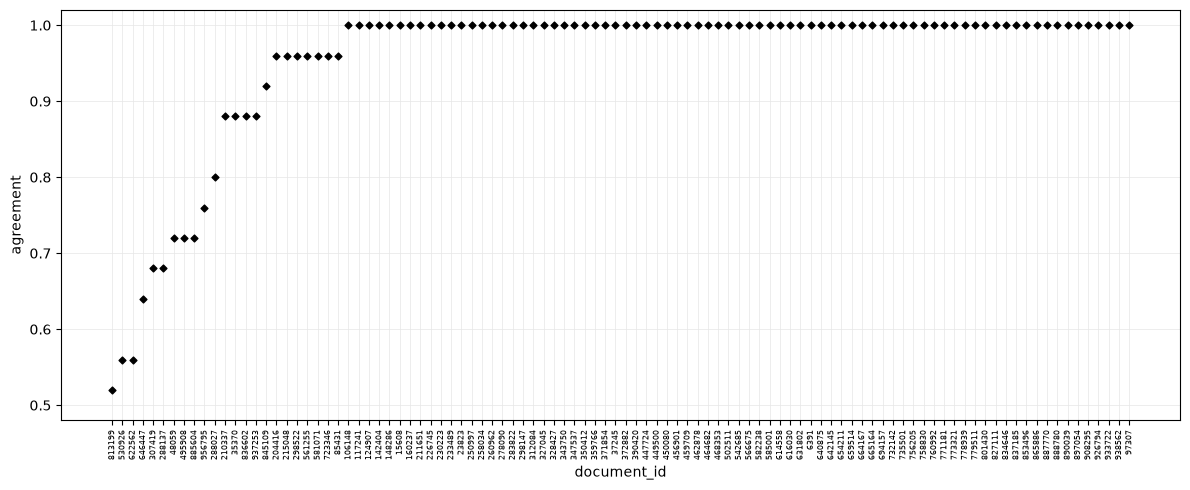

In [105]:
experiment.review(datasets=0)

## 2. Generate the first codebook
Generate version 1 using the initial coding summaries. Generation always streams. When submitted, it saves the codebook immediately and prints the saved path. Open that file to inspect the definition and rules.


In [114]:
experiment.generate_codebook_0(datasets=0, version=0, preview=False)


Saved: codebook version 0 (stream).


WindowsPath('C:/Users/yjjby/Documents/projects/Topic-Conceptualization/iterative_codebook_making/emotive_rhetoric_new_pipeline_fix_Aluna_Bdeepseek/out/codebooks/version-000/codebook.json')

## 3. Check the current codebook
This is the main work area. Choose a codebook version and the datasets to check here. After any revision, update `current_version` to the new number and rerun these cells.

`datasets=0` checks one dataset; `[0, 1]` checks both together. Every document ID must be unique across the selected files.


In [ ]:
current_version = 0
datasets_to_check = [0]


In [118]:
experiment.code(datasets=0, version=0, preview=False, mode = "stream",
                note="apply codebook_0 to dataset_0")


Run 1/25
Run 2/25
Run 3/25
Run 4/25
Run 5/25
Run 6/25
Run 7/25
Run 8/25
Run 9/25
Run 10/25
Run 11/25
Run 12/25
Run 13/25
Run 14/25
Run 15/25
Run 16/25
Run 17/25
Run 18/25
Run 19/25
Run 20/25
Run 21/25
Run 22/25
Run 23/25
Run 24/25
Run 25/25
Submitted/resumed: model A, datasets [0], version 0, 25 runs (stream). C:\Users\yjjby\Documents\projects\Topic-Conceptualization\iterative_codebook_making\emotive_rhetoric_new_pipeline_fix_Aluna_Bdeepseek\out\coding\datasets-0\version-000\model-A


Krippendorff's alpha: 0.9239


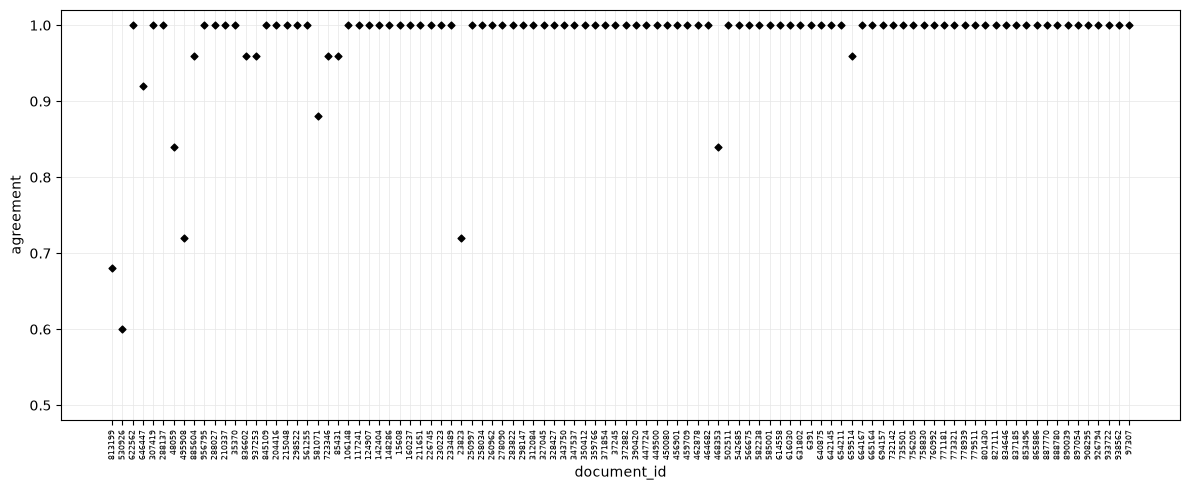

In [119]:
experiment.review(datasets=0, version=0)


### Decision: keep it or revise it
If satisfied, run the acceptance cell. Acceptance records your decision; it does not create another codebook version. Replace the note with your reason.


In [ ]:
# Optional: run only when you choose to keep this version.
experiment.accept(version=1, note='Model A applies codebook_1 to dataset_0, agreement is sufficient to move on -- 0.9508.')


Accepted version 1: Model A applies codebook_1 to dataset_0, agreement is sufficient to move on -- 0.9508.


If you need a revision, set the next unused version number explicitly. **Rerunning the same version resumes or reviews that task; it never increments the version automatically.** Choose a number higher than every version already used (see `experiment.status()`).

After opening and reviewing the saved codebook, update `current_version` above, then rerun the coding and review cells. There is no need to copy paths or load JSON manually.


In [ ]:
new_version = current_version + 1


In [ ]:
experiment.revise(
    datasets=0,
    source_version=0,
    version=1,
    preview=False,
    note="revise intial codebook 0, based on 1st coding of dataset 0 with codebook 0"
)


Saved: codebook version 1 (stream).


WindowsPath('C:/Users/yjjby/Documents/projects/Topic-Conceptualization/iterative_codebook_making/emotive_rhetoric_new_pipeline_fix/out/codebooks/version-001/codebook.json')

## 4. Test a new dataset
Use the current accepted version on a new dataset. Change `next_dataset` to the input file number you want to inspect.


In [139]:
experiment.code(datasets=3, version=3, preview=False, mode="stream")


Run 1/25
Run 2/25
Run 3/25
Run 4/25
Run 5/25
Run 6/25
Run 7/25
Run 8/25
Run 9/25
Run 10/25
Run 11/25
Run 12/25
Run 13/25
Run 14/25
Run 15/25
Run 16/25
Run 17/25
Run 18/25
Run 19/25
Run 20/25
Run 21/25
Run 22/25
Run 23/25
Run 24/25
Run 25/25
Submitted/resumed: model A, datasets [3], version 3, 25 runs (stream). C:\Users\yjjby\Documents\projects\Topic-Conceptualization\iterative_codebook_making\emotive_rhetoric_new_pipeline_fix_Aluna_Bdeepseek\out\coding\datasets-3\version-003-revise_w_newdata1_3\model-A


In [149]:
experiment.review(datasets=3, version=3)


Batch: in_progress. Rerun this review cell later.


If agreement is low, make an revision using the new dataset. Choose the next unused version number. After opening the saved codebook and reviewing it, update `current_version` in section 3 and set `datasets_to_check = [0, 1]` (or all datasets seen so far) to check the complete collection.


In [136]:
# Optional: uncomment when a new dataset requires revision.
experiment.revise(
    datasets=2,
    source_version=2,
    version=(2+1),
    suffix="revise_w_newdata1_3",
    preview=False,
)


Saved: codebook version 3 (stream).


WindowsPath('C:/Users/yjjby/Documents/projects/Topic-Conceptualization/iterative_codebook_making/emotive_rhetoric_new_pipeline_fix_Aluna_Bdeepseek/out/codebooks/version-003-revise_w_newdata1_3/codebook.json')

## 5. Compare models
Choose the same dataset collection and codebook for both models. Model A's existing coding is reused when available. Review each model, then compare their distributions and paired-run alpha.

The comparison prints mean absolute difference in proportions, Pearson correlation, and average nominal Krippendorff alpha for matching A/B run numbers. It shows a scatterplot with a diagonal and slight jitter, plus a document plot with A and B in different colors. Documents are ordered by A's percentage coded 1, highest to lowest; B uses the same order. Analysis outputs are displayed without saving tables or figures.


In [ ]:
comparison_datasets = [0, 1]


In [160]:
experiment.code(datasets=3, version=2, model="A", preview=False, mode="stream")
experiment.code(datasets=3, version=2, model="B", preview=False, mode="stream")


Run 1/25
Run 2/25
Run 3/25
Run 4/25
Run 5/25
Run 6/25
Run 7/25
Run 8/25
Run 9/25
Run 10/25
Run 11/25
Run 12/25
Run 13/25
Run 14/25
Run 15/25
Run 16/25
Run 17/25
Run 18/25
Run 19/25
Run 20/25
Run 21/25
Run 22/25
Run 23/25
Run 24/25
Run 25/25
Submitted/resumed: model A, datasets [3], version 2, 25 runs (stream). C:\Users\yjjby\Documents\projects\Topic-Conceptualization\iterative_codebook_making\emotive_rhetoric_new_pipeline_fix\out\coding\datasets-3\version-002\model-A
Run 1/25
Run 2/25
Run 3/25
Run 4/25
Run 5/25
Run 6/25
Run 7/25
Run 8/25
Run 9/25
Run 10/25
Run 11/25
Run 12/25
Run 13/25
Run 14/25
Run 15/25
Run 16/25
Run 17/25
Run 18/25
Run 19/25
Run 20/25
Run 21/25
Run 22/25
Run 23/25
Run 24/25
Run 25/25
Submitted/resumed: model B, datasets [3], version 2, 25 runs (stream). C:\Users\yjjby\Documents\projects\Topic-Conceptualization\iterative_codebook_making\emotive_rhetoric_new_pipeline_fix\out\coding\datasets-3\version-002\model-B


In [ ]:
experiment.review(datasets=comparison_datasets, version=current_version, model="A")


Krippendorff's alpha: 0.8419


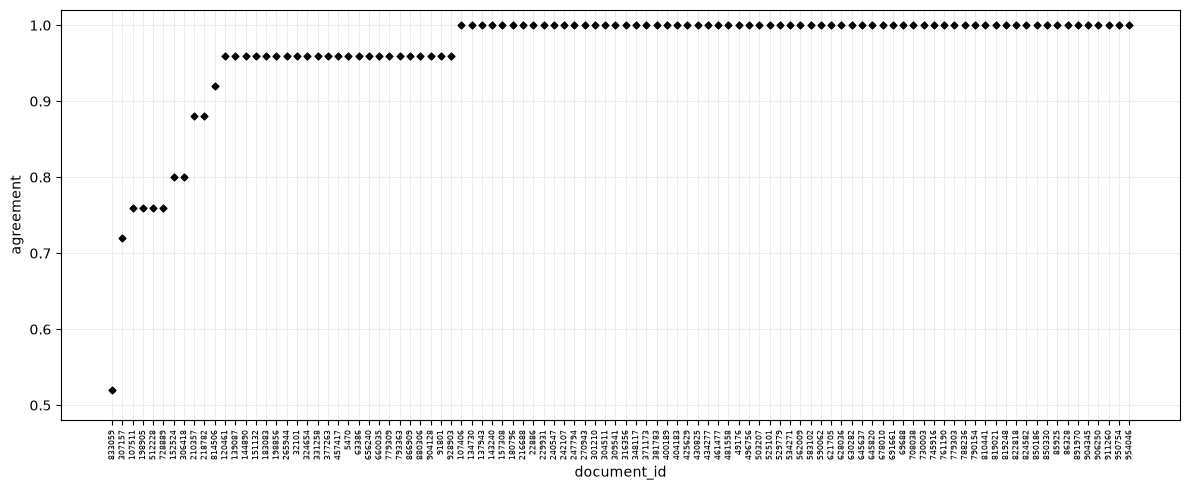

In [161]:
experiment.review(datasets=3, version=2, model="A")


Mean abs difference in label-1 proportions: 0.0598
Model correlation: 0.9149
Mean paired-run alpha: 0.7976
SD of paired-run alpha: 0.0452
Paired-run alphas:
Run 01: 0.7818
Run 02: 0.7818
Run 03: 0.7119
Run 04: 0.8167
Run 06: 0.7753
Run 07: 0.7877
Run 08: 0.7753
Run 09: 0.9170
Run 10: 0.7931
Run 11: 0.8840
Run 12: 0.7877
Run 13: 0.7753
Run 14: 0.8117
Run 15: 0.8363
Run 16: 0.8363
Run 17: 0.7643
Run 18: 0.7818
Run 19: 0.8655
Run 20: 0.7509
Run 21: 0.7579
Run 22: 0.8167
Run 23: 0.7681
Run 24: 0.7643
Run 25: 0.8003


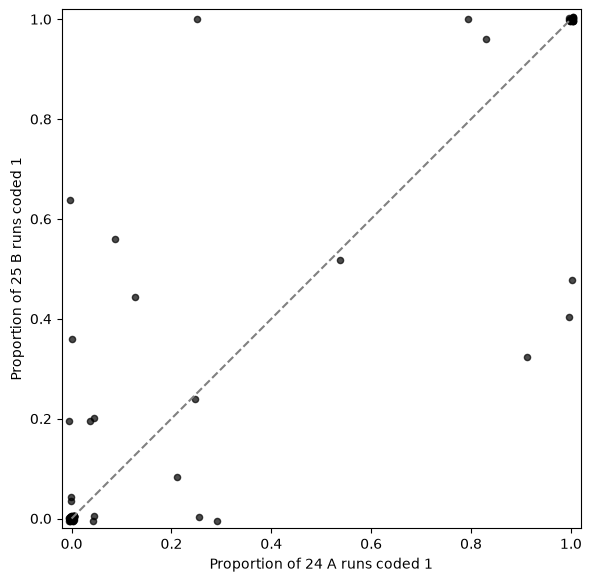

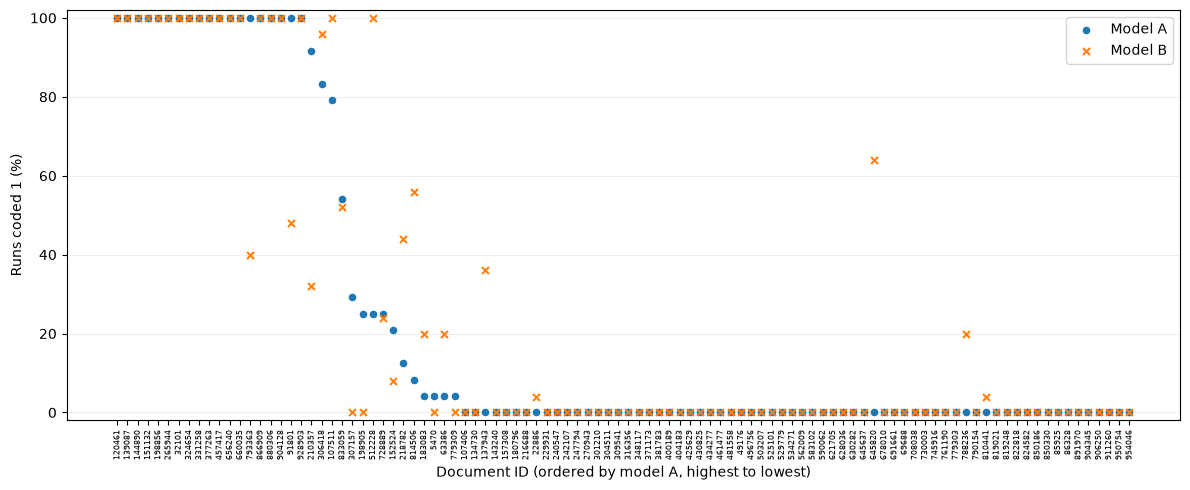

In [6]:
experiment.compare(datasets=3, version=2)

### Optional: revise using both models
After A and B have coded the same documents with the same codebook version, set `crossmodel=True` to supply both summaries. A writes the revision using `improve_codebook crossmodel.txt`. Review that prompt before running. Choose an unused version number.


In [11]:
experiment.revise(
    datasets=3, source_version=2,
    version=3, crossmodel=True,
    prompt_file="improve_codebook_crossmodel.txt",
    note="Use B disagreements to clarify A interpretation", preview=False,
)


Saved: codebook version 3 (stream).


WindowsPath('C:/Users/yjjby/Documents/projects/Topic-Conceptualization/iterative_codebook_making/emotive_rhetoric_new_pipeline_fix/out/codebooks/version-003/codebook.json')

## Resume or inspect progress
After a kernel restart, rerun setup and set `current_version` and your dataset selections. All requests and results remain on disk. This status cell reads local files without API calls.

Saved files live in `emotive_rhetoric/out/`:

```text
coding/datasets-0/no-codebook/model-A/       initial coding
coding/datasets-0/version-001/model-A/      coding using version 1
coding/datasets-0-1/version-002/model-B/    cumulative coding by B
codebooks/version-001/codebook.json         full codebook
codebooks/version-002/documentation.json    revision notes
orders/datasets-0.json                      reusable plot order
```

Request/response files and input snapshots stay inside their task folders. Each task records its inputs and rejects changed settings rather than mixing results. To change models, prompts, mode, or run count for an existing task, start another `session_dir`.


In [32]:
experiment.status()


shape: (7, 2)
┌─────────────────────────────────┬───────────┐
│ task                            ┆ state     │
│ ---                             ┆ ---       │
│ str                             ┆ str       │
╞═════════════════════════════════╪═══════════╡
│ codebooks\version-000           ┆ accepted  │
│ codebooks\version-001-revise_w… ┆ completed │
│ coding\datasets-0\no-codebook\… ┆ completed │
│ coding\datasets-0\version-000\… ┆ completed │
│ coding\datasets-0-1\version-00… ┆ completed │
│ coding\datasets-0-1\version-00… ┆ completed │
│ coding\datasets-1\version-000\… ┆ completed │
└─────────────────────────────────┴───────────┘
